# Инференс Gemma 3: базовая загрузка и prompt-эксперименты

Наброски использования Transformers pipeline и генерации ответов Gemma 3; оставлен как вспомогательный эксперимент.

In [1]:
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

# Загрузка модели, токенизация, генерация ответа

In [22]:
model = AutoModelForCausalLM.from_pretrained('google/gemma-3-270m-it', dtype='auto', device_map='auto')
tokenizer = AutoTokenizer.from_pretrained('google/gemma-3-270m-it')

In [23]:
model_inputs = tokenizer('Кто ты?', return_tensors='pt', padding=True).to(model.device)

In [24]:
model_inputs

{'input_ids': tensor([[     2, 202611,  19949, 236881]], device='cuda:0'), 'attention_mask': tensor([[1, 1, 1, 1]], device='cuda:0')}

In [25]:
generated_ids = model.generate(**model_inputs)
generated_ids

Setting `pad_token_id` to `eos_token_id`:1 for open-end generation.


tensor([[     2, 202611,  19949, 236881,    107,   1018,  51426,  19949, 130622,
         236881,   1018,    108,  13836,   2186,  56368, 236764,  19949,  47549,
         236888,    107,   1018, 158624,   6377,   1754]], device='cuda:0')

In [26]:
tokenizer.decode(generated_ids.squeeze(), skip_special_tokens=True)

'Кто ты?\n**Что ты сделал?**\n\nНадеюсь, ты хорошо!\n**Есть ли у'

In [48]:
message = [
    {'role': 'system', 'content': 'Отвечай на английском'},
    {'role': 'user', 'content': 'Кто ты?'}
]
tokenized_message = tokenizer.apply_chat_template(message, tokenize=True, return_tensors='pt', add_generation_prompt=True).to(model.device)
n = sum(len(tokenizer.decode(token)) for token in tokenized_message)
tokenized_message

tensor([[     2,    105,   2364,    107,  36007,   2687,  79746,   1333,  80327,
          22357,    108, 202611,  19949, 236881,    106,    107,    105,   4368,
            107]], device='cuda:0')

In [57]:
generated_ids = model.generate(tokenized_message, max_new_tokens=128)
tokenizer.decode(generated_ids.squeeze(), skip_special_tokens=True)[n:]

The attention mask and the pad token id were not set. As a consequence, you may observe unexpected behavior. Please pass your input's `attention_mask` to obtain reliable results.
Setting `pad_token_id` to `eos_token_id`:1 for open-end generation.


'Google DeepMind. I am an open-source image understanding and generation model.\n'

# Pipelines

In [1]:
from transformers import pipeline
from accelerate import Accelerator

W0222 15:53:23.483000 13048 site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


In [2]:
device = Accelerator().device

In [30]:
pipeline1 = pipeline('text-generation', model='google/gemma-3-270m', device=device)

Loading weights:   0%|          | 0/236 [00:00<?, ?it/s]

In [35]:
pipeline1('Я сегодня ел на обед', max_new_tokens=None, max_length=None)

[{'generated_text': 'Я сегодня ел на обед, мы были в другом отеле. В общем, очень хорошее'}]

In [7]:
pipeline2 = pipeline('image-segmentation', model='facebook/detr-resnet-50-panoptic', device=device)

Loading weights:   0%|          | 0/562 [00:00<?, ?it/s]

The image processor of type `DetrImageProcessor` is now loaded as a fast processor by default, even if the model checkpoint was saved with a slow processor. This is a breaking change and may produce slightly different outputs. To continue using the slow processor, instantiate this class with `use_fast=False`. 


In [6]:
segments

[{'score': 0.984346,
  'label': 'cat',
  'mask': <PIL.Image.Image image mode=L size=984x1280>},
 {'score': 0.998924,
  'label': 'cup',
  'mask': <PIL.Image.Image image mode=L size=984x1280>},
 {'score': 0.986553,
  'label': 'LABEL_199',
  'mask': <PIL.Image.Image image mode=L size=984x1280>},
 {'score': 0.931795,
  'label': 'dining table',
  'mask': <PIL.Image.Image image mode=L size=984x1280>},
 {'score': 0.943857,
  'label': 'chair',
  'mask': <PIL.Image.Image image mode=L size=984x1280>}]

In [21]:
import matplotlib.pyplot as plt
from math import ceil
import numpy as np
from PIL import Image

In [34]:
def masked_img(img, mask):
    m = mask.copy()
    m = np.array(m)
    m = (m != 0).astype(int)
    m = np.tile(m[None, ...], (3, 1, 1))
    m = m.transpose(1, 2, 0)
    return m * img

In [51]:
img_path = r'../../data/images/kirill.jpg'
segments = pipeline2(img_path)

In [52]:
segments

[{'score': 0.966446,
  'label': 'LABEL_193',
  'mask': <PIL.Image.Image image mode=L size=960x1280>},
 {'score': 0.992464,
  'label': 'LABEL_184',
  'mask': <PIL.Image.Image image mode=L size=960x1280>},
 {'score': 0.999939,
  'label': 'person',
  'mask': <PIL.Image.Image image mode=L size=960x1280>}]

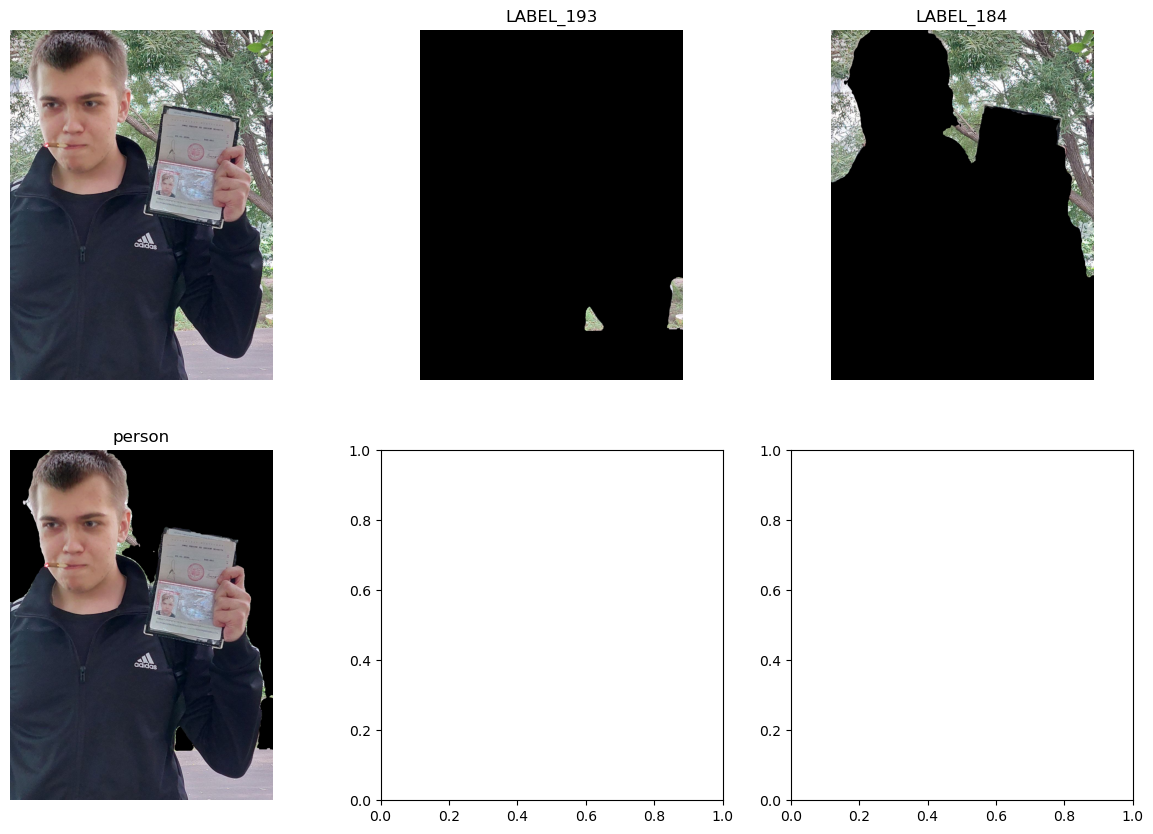

In [53]:
image = Image.open(img_path)

n = len(segments)
cols = 3
rows = ceil((n + 1) / cols)
fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 5 * rows))
axes = np.array(axes).flatten()

axes[0].imshow(image)
axes[0].axis('off')
for i in range(n):
    ax = axes[i+1]
    segm = masked_img(image, segments[i]['mask'])
    ax.imshow(segm)
    ax.set_title(segments[i]['label'])
    ax.axis('off')